<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · The index did not change; its eligibility did

When is a drop in a parcel's optical index a usable comparison? We will process two small parcels through cloud masking, inspect each observation's clear-pixel coverage, and compare individual acquisitions with monthly composites. Then we will raise the minimum coverage requirement while holding the raster inputs fixed. The question is whether the same measured values still support the same comparison.

**All inputs are explicitly synthetic.** The pinned worker ships three tiny optical scenes and two polygon fixtures, designed to have known answers. June 1 has a red/NIR contrast, June 15 is fully masked, and July 1 has equal red/NIR values. These dated labels organize the constructed example; they are not satellite observations or a field study. No public API, live account, external imagery or fabricated replacement for failed data is used. The real raster implementation executes through VGI against the bundled TIFFs.

## Choose an eligibility threshold

`MIN_COVERAGE` is a fraction from **0 to 1**, inclusive. Default **0.50** permits an observed mean to participate in temporal comparisons when at least half the parcel's grid-cell centres have usable values. The experiment uses **0.90**. A nonempty mean can remain visible below the threshold; it is marked `insufficient_coverage` and is excluded from the change calculation. No usable pixels means the mean is NULL.

The fixed UTC source window is **2026-06-01T00:00:00Z through 2026-07-01T00:00:00Z, both endpoints inclusive**. Geometry WKB uses **EPSG:32618**, X/Y order, metres. Pixel-centre membership, not fractional polygon overlap, determines counts. Restart Kernel → Run All after editing.

In [1]:
MIN_COVERAGE = 0.50  # fraction 0..1 inclusive; experiment: 0.90

In [2]:
import hashlib
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.lines import Line2D

assert isinstance(MIN_COVERAGE, (float, int)) and not isinstance(MIN_COVERAGE, bool)
assert np.isfinite(MIN_COVERAGE) and 0 <= MIN_COVERAGE <= 1
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)
colors = {"field-a": "#0072b2", "field-b": "#d55e00"}


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Synthetic bundled optical fixtures · UTC 2026-06-01 to 2026-07-01 inclusive · coverage cutoff {MIN_COVERAGE:.0%}",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.9))
    plt.show()


secret_directory = TemporaryDirectory(prefix="earth-observation-notebook-secrets-")
con = haybarn.connect(config={"secret_directory": secret_directory.name, "allow_persistent_secrets": False})
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
Path("artifacts").mkdir(exist_ok=True)
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/vgi-earth-observation/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-earth-observation/notebooks/pyproject.toml.

## Materialize the same parcels and scenes three ways

The visible launch pins the remotely published source commit and tested worker dependencies. It runs from this notebook directory alone. The worker's `demo://scenes.json` resolves to package data, not a path in this checkout.

`reference_observations` retains every computed observation using a zero coverage threshold. `selected_observations` applies the chosen threshold. `monthly_series` applies the same threshold after a **per-pixel temporal median**, followed by the spatial mean over usable parcel pixels. These are three deliberate deterministic worker calls. Subsequent aggregation and plotting use ordinary in-memory tables only.

The explicit limits exceed these tiny fixtures but reject unexpectedly large scene lists or raster windows. The NDVI calculation is `(NIR − red) / (NIR + red)` after calibration and masking; it is dimensionless. A zero NDVI is a measured contrast, not a missing observation.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'earth_observation' (
 TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-earth-observation.git@542b71d763991e2bd8176f31920298f2e1a8925b --constraints worker-constraints.txt vgi-earth-observation-worker'
);
CREATE TABLE parcels AS SELECT * FROM earth_observation.demo_input;
CREATE TABLE reference_observations AS
SELECT * FROM earth_observation.parcel_series((SELECT * FROM parcels),
 catalog := 'demo://scenes.json', geometry_crs := 'EPSG:32618',
 start_date := '2026-06-01T00:00:00Z', end_date := '2026-07-01T00:00:00Z',
 composite := 'observation', min_coverage := 0.0, max_scenes := 3,
 max_pages := 1, max_pixels := 100, max_source_pixels := 100,
 decline_threshold := 0.3, max_change_gap_days := 90.0);
CREATE TABLE selected_observations AS
SELECT * FROM earth_observation.parcel_series((SELECT * FROM parcels),
 catalog := 'demo://scenes.json', geometry_crs := 'EPSG:32618',
 start_date := '2026-06-01T00:00:00Z', end_date := '2026-07-01T00:00:00Z',
 composite := 'observation', min_coverage := {{MIN_COVERAGE}}, max_scenes := 3,
 max_pages := 1, max_pixels := 100, max_source_pixels := 100,
 decline_threshold := 0.3, max_change_gap_days := 90.0);
CREATE TABLE monthly_series AS
SELECT * FROM earth_observation.parcel_series((SELECT * FROM parcels),
 catalog := 'demo://scenes.json', geometry_crs := 'EPSG:32618',
 start_date := '2026-06-01T00:00:00Z', end_date := '2026-07-01T00:00:00Z',
 composite := 'month', min_coverage := {{MIN_COVERAGE}}, max_scenes := 3,
 max_pages := 1, max_pixels := 100, max_source_pixels := 100,
 decline_threshold := 0.3, max_change_gap_days := 90.0);

,Count


In [4]:
reference = con.execute(
    "SELECT parcel_id,observed_at,index_name,mean_index,valid_pixels,total_pixels,coverage_fraction,scene_ids,calibration,analysis_crs FROM reference_observations ORDER BY parcel_id,observed_at"
).df()
fingerprint = hashlib.sha256(reference.to_json(orient="records", date_format="iso").encode()).hexdigest()
prose(
    f"The worker returned **{len(reference)} parcel-observation rows** for **{reference.parcel_id.nunique()} parcels** at **{reference.observed_at.nunique()} acquisition labels**. Fingerprint of all reference measurements: `{fingerprint}`. This fingerprint deliberately excludes the eligibility status and change fields, so the threshold experiment can verify that its input measurements stayed fixed. Band calibration and scene identities contribute to the fingerprint and remain in the audit; the polygon fixtures are fixed by the published source revision."
)

The worker returned **6 parcel-observation rows** for **2 parcels** at **3 acquisition labels**. Fingerprint of all reference measurements: `d9ebcb34c56ceed760b42946865779fdba6c2e0f4d31b78432230a901b6c5bd8`. This fingerprint deliberately excludes the eligibility status and change fields, so the threshold experiment can verify that its input measurements stayed fixed. Band calibration and scene identities contribute to the fingerprint and remain in the audit; the polygon fixtures are fixed by the published source revision.

## Check coverage and reconstruct eligibility in SQL

Keep `valid_pixels`, `total_pixels` and `coverage_fraction` together. The threshold is inclusive. Coverage is an observed fraction of grid-cell centres, not a confidence probability or a measure of cloud-free area with fractional edge weights.

We independently reconstruct the prior eligible observation within each parcel. An unavailable or rejected row does not become a zero-valued baseline. A comparison is permitted only when the previous eligible observation is at most 90 days earlier; a decline flag means a change of at least 0.3 NDVI units in the negative direction.

In [5]:
%%sql
CREATE TABLE eligible_history AS
SELECT parcel_id,observed_at,
 mean_index-lag(mean_index) OVER(PARTITION BY parcel_id ORDER BY observed_at) AS candidate_delta,
 date_diff('second',lag(observed_at) OVER(PARTITION BY parcel_id ORDER BY observed_at),observed_at)/86400.0 AS gap_days
FROM selected_observations
WHERE mean_index IS NOT NULL AND coverage_fraction >= {{MIN_COVERAGE}};
CREATE TABLE reconciled AS
SELECT s.*, CASE WHEN e.gap_days<=90 THEN e.candidate_delta END AS expected_delta,
 CASE WHEN mean_index IS NOT NULL AND coverage_fraction >= {{MIN_COVERAGE}}
      THEN 'ok' ELSE 'insufficient_coverage' END AS expected_status
FROM selected_observations s LEFT JOIN eligible_history e USING(parcel_id,observed_at);

,Count


In [6]:
%%sql checks <<
SELECT
 (SELECT count(*)-count(DISTINCT(parcel_id,observed_at)) FROM selected_observations) AS duplicate_keys,
 (SELECT count(*) FROM selected_observations s FULL JOIN reference_observations r USING(parcel_id,observed_at)
  WHERE s.mean_index IS DISTINCT FROM r.mean_index OR s.valid_pixels IS DISTINCT FROM r.valid_pixels
     OR s.total_pixels IS DISTINCT FROM r.total_pixels OR s.calibration IS DISTINCT FROM r.calibration) AS changed_measurements,
 count(*) FILTER(WHERE total_pixels<=0 OR valid_pixels<0 OR valid_pixels>total_pixels) AS invalid_counts,
 count(*) FILTER(WHERE abs(coverage_fraction-valid_pixels::DOUBLE/total_pixels)>1e-12) AS coverage_mismatches,
 count(*) FILTER(WHERE (mean_index IS NULL)<>(valid_pixels=0)) AS missing_value_mismatches,
 count(*) FILTER(WHERE status<>expected_status) AS status_mismatches,
 count(*) FILTER(WHERE (delta_index IS NULL)<>(expected_delta IS NULL)
    OR abs(delta_index-expected_delta)>1e-12) AS delta_mismatches,
 count(*) FILTER(WHERE decline IS DISTINCT FROM (expected_delta<=-0.3)) AS flag_mismatches
FROM reconciled;

In [7]:
display(checks)
assert checks.iloc[0].eq(0).all()
assert len(reference) > 0 and reference.analysis_crs.eq("EPSG:32618").all()
assert (
    con.execute(
        "SELECT count(*) FROM selected_observations WHERE observed_at<TIMESTAMP '2026-06-01' OR observed_at>TIMESTAMP '2026-07-01'"
    ).fetchone()[0]
    == 0
)
prose(
    "All coverage, unchanged-measurement, eligibility and reconstructed-change checks pass. These are internal consistency checks on a constructed fixture and the worker's documented rules; they do not validate a remote sensor, cloud classifier or vegetation diagnosis."
)

,duplicate_keys,changed_measurements,invalid_counts,coverage_mismatches,missing_value_mismatches,status_mismatches,delta_mismatches,flag_mismatches
0,0,0,0,0,0,0,0,0


All coverage, unchanged-measurement, eligibility and reconstructed-change checks pass. These are internal consistency checks on a constructed fixture and the worker's documented rules; they do not validate a remote sensor, cloud classifier or vegetation diagnosis.

In [8]:
%%sql observations <<
SELECT parcel_id,observed_at::DATE AS observation_date,mean_index,
 valid_pixels,total_pixels,coverage_fraction,status,delta_index,decline
FROM selected_observations ORDER BY parcel_id,observed_at;

,parcel_id,observation_date,mean_index,valid_pixels,total_pixels,coverage_fraction,status,delta_index,decline
0,field-a,2026-06-01,6.000000e-01,12,16,0.75,ok,NaN,<NA>
1,field-a,2026-06-15,NaN,0,16,0.00,insufficient_coverage,NaN,<NA>
2,field-a,2026-07-01,6.938894e-18,16,16,1.00,ok,-0.6,True
3,field-b,2026-06-01,6.000000e-01,8,8,1.00,ok,NaN,<NA>
4,field-b,2026-06-15,NaN,0,8,0.00,insufficient_coverage,NaN,<NA>
5,field-b,2026-07-01,1.387779e-17,8,8,1.00,ok,-0.6,True


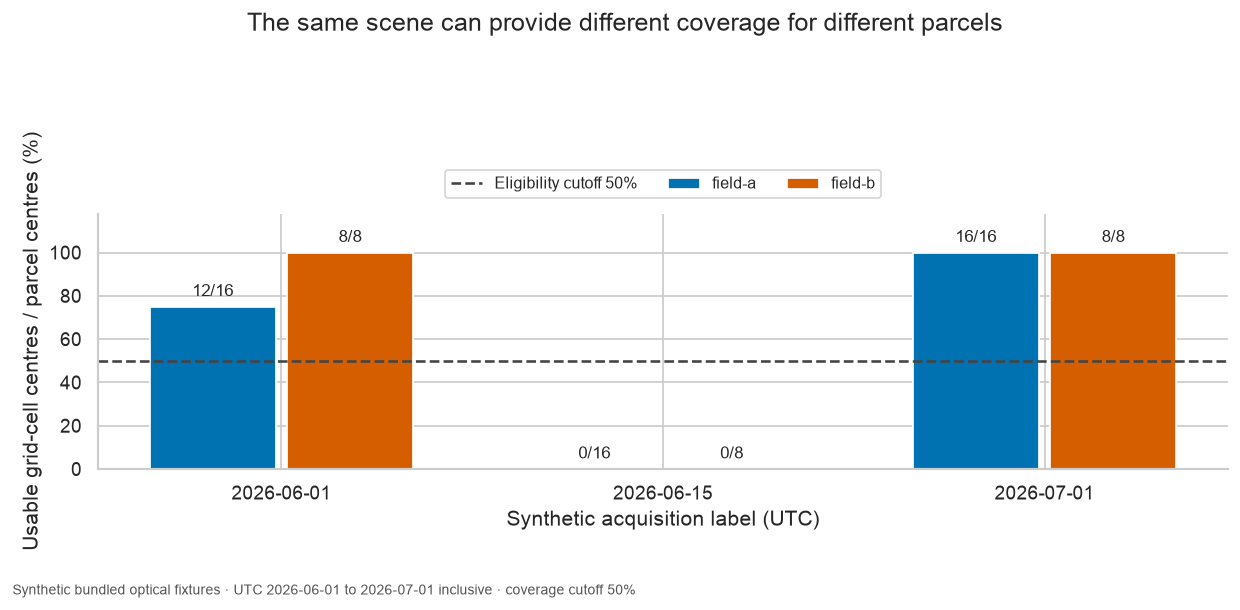

At **50%**, **4 of 6 observation rows** are eligible. **Rows retaining an index below cutoff: 0. Rows with no usable index: 2.** Bar labels are valid/total pixel-centre counts. The two parcels share scenes but cover different raster cells; treating a scene-level cloud label as parcel coverage would miss this distinction.

In [9]:
display(observations)
labels = [str(d.date()) for d in pd.to_datetime(sorted(observations.observation_date.unique()))]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(10, 4.8))
for offset, (parcel, color) in zip([-0.18, 0.18], colors.items(), strict=True):
    data = observations[observations.parcel_id.eq(parcel)].sort_values("observation_date")
    bars = ax.bar(x + offset, data.coverage_fraction * 100, width=0.33, color=color, label=parcel)
    ax.bar_label(
        bars, labels=[f"{r.valid_pixels}/{r.total_pixels}" for r in data.itertuples()], padding=4, fontsize=10
    )
ax.axhline(
    MIN_COVERAGE * 100, color="#444444", linestyle="--", label=f"Eligibility cutoff {MIN_COVERAGE:.0%}"
)
ax.set(
    xticks=x,
    xticklabels=labels,
    ylim=(0, 118),
    ylabel="Usable grid-cell centres / parcel centres (%)",
    xlabel="Synthetic acquisition label (UTC)",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=3, fontsize=9)
fig.suptitle("The same scene can provide different coverage for different parcels")
finish(fig)
usable = int(observations.status.eq("ok").sum())
partial = int((observations.mean_index.notna() & observations.status.ne("ok")).sum())
missing = int(observations.mean_index.isna().sum())
prose(
    f"At **{MIN_COVERAGE:.0%}**, **{usable} of {len(observations)} observation rows** are eligible. **Rows retaining an index below cutoff: {partial}. Rows with no usable index: {missing}.** Bar labels are valid/total pixel-centre counts. The two parcels share scenes but cover different raster cells; treating a scene-level cloud label as parcel coverage would miss this distinction."
)

## A monthly row can conceal an unavailable acquisition

A monthly composite uses the pixelwise median over valid observations. In this fixture, the fully masked June scene contributes no valid samples. June still has a monthly mean based on the usable scene, and `scene_count=2` records that both scenes were considered. It does not mean two independent valid measurements supported every pixel.

The table retains the contributing scene ids and the count denominator. Monthly `observed_at` labels the first UTC day of the month, not an actual acquisition time. The charts retain the missing individual acquisition as a shaded time marker. Solid markers are eligible observations; hollow markers have a measured index but fail coverage. Dashed monthly lines show aggregation, not an observation through the cloudy date.

In [10]:
%%sql monthly <<
SELECT parcel_id,observed_at::DATE AS month_label,mean_index,valid_pixels,total_pixels,
 coverage_fraction,scene_count,scene_ids,status,delta_index,decline
FROM monthly_series ORDER BY parcel_id,observed_at;

In [11]:
%%sql diagnostics <<
SELECT parcel_id,count(*) AS observation_rows,count(mean_index) AS measured_rows,
 count(*) FILTER(WHERE status='ok') AS eligible_rows,count(delta_index) AS comparisons,
 count(*) FILTER(WHERE decline) AS declines
FROM selected_observations GROUP BY parcel_id ORDER BY parcel_id;

,parcel_id,month_label,mean_index,valid_pixels,total_pixels,coverage_fraction,scene_count,scene_ids,status,delta_index,decline
0,field-a,2026-06-01,6.000000e-01,12,16,0.75,2,"[""scene-0"", ""scene-1""]",ok,NaN,<NA>
1,field-a,2026-07-01,6.938894e-18,16,16,1.00,1,"[""scene-2""]",ok,-0.6,True
2,field-b,2026-06-01,6.000000e-01,8,8,1.00,2,"[""scene-0"", ""scene-1""]",ok,NaN,<NA>
3,field-b,2026-07-01,1.387779e-17,8,8,1.00,1,"[""scene-2""]",ok,-0.6,True


,parcel_id,observation_rows,measured_rows,eligible_rows,comparisons,declines
0,field-a,3,2,2,1,1
1,field-b,3,2,2,1,1


/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/ipykernel_10439/2852828093.py:18: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax.axvspan(when - pd.Timedelta(days=1), when + pd.Timedelta(days=1), color="#dddddd", alpha=0.55)
/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/ipykernel_10439/2852828093.py:18: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax.axvspan(when - pd.Timedelta(days=1), when + pd.Timedelta(days=1), color="#dddddd", alpha=0.55)


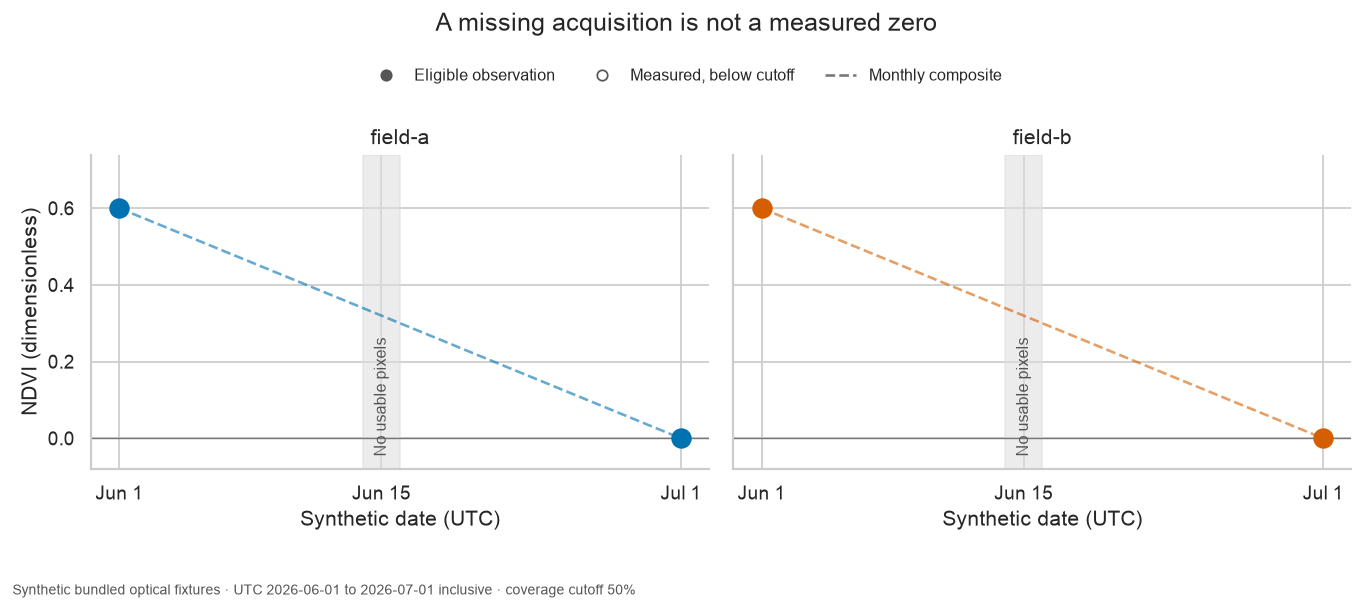

**Eligible temporal comparisons: 2. Decline flags at −0.3: 2.** Monthly aggregation returns **4 parcel-month rows** from **6 parcel-observation rows**. The July index is numerically near zero because its constructed NIR and red values are equal; the cloudy June acquisition is NULL. A coverage rule can remove a comparison without changing either measured endpoint. NDVI change alone does not identify a cause or establish crop stress.

6881

In [12]:
display(monthly)
display(diagnostics)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
for ax, (parcel, color) in zip(axes, colors.items(), strict=True):
    obs = observations[observations.parcel_id.eq(parcel)].sort_values("observation_date")
    mon = monthly[monthly.parcel_id.eq(parcel)].sort_values("month_label")
    ax.plot(
        pd.to_datetime(mon.month_label),
        mon.mean_index,
        linestyle="--",
        color=color,
        alpha=0.6,
        label="Monthly pixel composite",
    )
    for row in obs.itertuples():
        when = pd.Timestamp(row.observation_date)
        if pd.isna(row.mean_index):
            ax.axvspan(when - pd.Timedelta(days=1), when + pd.Timedelta(days=1), color="#dddddd", alpha=0.55)
            ax.text(
                when,
                0.04,
                "No usable pixels",
                rotation=90,
                ha="center",
                va="bottom",
                transform=ax.get_xaxis_transform(),
                fontsize=9,
                color="#555555",
            )
        else:
            ax.scatter(
                when,
                row.mean_index,
                s=95,
                facecolor=color if row.status == "ok" else "white",
                edgecolor=color,
                linewidth=2,
                zorder=3,
            )
    ax.axhline(0, color="#777777", linewidth=0.8)
    ax.set(title=parcel, ylim=(-0.08, 0.74), xlabel="Synthetic date (UTC)")
    ax.set_xticks(pd.to_datetime(labels), ["Jun 1", "Jun 15", "Jul 1"])
axes[0].set_ylabel("NDVI (dimensionless)")
handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#555555",
        markeredgecolor="#555555",
        label="Eligible observation",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="white",
        markeredgecolor="#555555",
        label="Measured, below cutoff",
    ),
    Line2D([0], [0], linestyle="--", color="#777777", label="Monthly composite"),
]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=3, fontsize=9, frameon=False)
fig.suptitle("A missing acquisition is not a measured zero")
finish(fig)
comparisons = int(diagnostics.comparisons.sum())
declines = int(diagnostics.declines.sum())
prose(
    f"**Eligible temporal comparisons: {comparisons}. Decline flags at −0.3: {declines}.** Monthly aggregation returns **{len(monthly)} parcel-month rows** from **{len(observations)} parcel-observation rows**. The July index is numerically near zero because its constructed NIR and red values are equal; the cloudy June acquisition is NULL. A coverage rule can remove a comparison without changing either measured endpoint. NDVI change alone does not identify a cause or establish crop stress."
)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "min_coverage": MIN_COVERAGE,
            "fingerprint": fingerprint,
            "reference": json.loads(reference.to_json(orient="records", date_format="iso")),
            "observations": json.loads(observations.to_json(orient="records", date_format="iso")),
            "monthly": json.loads(monthly.to_json(orient="records", date_format="iso")),
            "diagnostics": diagnostics.to_dict(orient="records"),
            "checks": checks.to_dict(orient="records"),
        },
        indent=2,
    )
)

## Experiment: require 90% usable coverage

Change only `MIN_COVERAGE` from **0.50 to 0.90**. Predict that field-a's partly observed June mean stays visible but loses eligibility, so its July value has no earlier eligible baseline. Field-b should retain its comparison. Compare the measured-input fingerprint, coverage bars, statuses, NULL change fields and decline counts. The raster data, mean values and fully cloudy rows must remain unchanged. Restore **0.50** afterwards.

The exercise shows sensitivity to an explicit analysis rule on fixed synthetic data. It is not evidence about any real location, classifier quality, agricultural outcome or suitable operational cutoff. For real imagery, retain source versions, calibration metadata, CRS, masks, date bounds and resource limits alongside the result; cloud coverage and temporal gaps are part of the result, not optional cleanup.

In [13]:
con.close()
secret_directory.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)